# Dar_024 — Nominal thermal-bin spatial support sensitivity

Environmental EDA supporting Moon base-location comparison with terrain. Existing data only; no mission/equipment policy is adopted.

## Questions

- Q39: What nominal bin size is explicitly documented in the downloaded Diviner label?
- Q40: How much of a declared nominal square around each associated center overlaps its component?
- Q41: Does that diagnostic change with 120/240/480 m square size?
- Q42: Which component examples have no fully overlapping nominal 240 m boxes?
- Q43: How do product counts and temperature summaries change under overlap-cohort cuts?
- Q44: Does the zero-cut identity control reproduce Dar_020 exactly, retaining empty groups?

## Input contract, comparisons and limitations

The downloaded PDS description explicitly says binned at 240 m resolution. We use nominal axis-aligned 120/240/480 m squares around accepted projected centers, NOT a reconstruction of exact native grid affine, instrument FOV or physical co-registration. The normalized source x/y field descriptions/unit tags are not reinterpreted; accepted longitude/latitude-derived coordinates are reused. Exact intersections are conditional on this declared square/lattice model. Overlap cuts (0,.25,.5,.75,1) select diagnostic cohorts, not adopted quality limits. Do not weight/unmix a brightness temperature by its overlap fraction.

In [1]:
from pathlib import Path
import sys,json
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'outline.md').is_file() and (p/'notebooks').is_dir())
sys.path[:0]=[str(ROOT/'darrel stuff/EDA'),str(ROOT)]
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
from environment_workflow import LocalRun as Run,latest_completed_run
from decision_eda import accepted_input
from site_comparison import cohort_rows
from environmental_selection_eda import candidate_thermal_profiles
from terrain_followup_eda import (SDEM_VARIABLES,terrain_source_statistics,slope_classification_comparison,
    candidate_source_support,illumination_roughness,sample_sdem_products,documented_nominal_bin_size,
    nominal_box_overlap,conditional_rank_relationship)
import terrain_followup_eda as methods
REGION_LIMIT=None  # First execute with 1; None is the complete seven-region scope.
spatial=latest_completed_run(ROOT,'analysis/dar_019_spatial_environment','20261106T175056432784Z_dfd0ab')
candidate=latest_completed_run(ROOT,'analysis/dar_020_candidate_environment','20261106T175311055762Z_b68ce6')
joint=latest_completed_run(ROOT,'analysis/dar_012_joint_environment','20261106T134155791814Z_c6f9ab')
thermal=latest_completed_run(ROOT,'analysis/dar_001_temperature_local_time','20261106T082643415392Z_4e6a0b')
environment=latest_completed_run(ROOT,'analysis/dar_002_temperature_environment','20261106T082929336242Z_623f9f')
sdem=latest_completed_run(ROOT,'lunar_terrain_environment','20261106T180253772848Z_40d3f3')
def regions_in(values):
    regions=sorted(values)
    if REGION_LIMIT is not None:
        if type(REGION_LIMIT) is not int or not 1<=REGION_LIMIT<=len(regions):raise ValueError('Invalid region limit')
        regions=regions[:REGION_LIMIT]
    return regions
def register(run):
    run.input(Path(methods.__file__))
    for name in ['decision_eda.py','moon_p1_analysis.py','site_comparison.py','environmental_selection_eda.py']:
        run.input(ROOT/'darrel stuff/EDA'/name)
def savefig(run,fig,name):
    fig.savefig(run.path(name+'.png'),dpi=120,bbox_inches='tight');display(fig);plt.close(fig)
def publish(run,record):
    run.path('findings.json').write_text(json.dumps(record,indent=2,default=str),encoding='utf-8');display(record)

Accepted local analysis/dar_019_spatial_environment run: 20261106T175056432784Z_dfd0ab
Accepted local analysis/dar_020_candidate_environment run: 20261106T175311055762Z_b68ce6
Accepted local analysis/dar_012_joint_environment run: 20261106T134155791814Z_c6f9ab
Accepted local analysis/dar_001_temperature_local_time run: 20261106T082643415392Z_4e6a0b
Accepted local analysis/dar_002_temperature_environment run: 20261106T082929336242Z_623f9f
Accepted local lunar_terrain_environment run: 20261106T180253772848Z_40d3f3


## Execute the bounded comparison

Completed source runs are pinned and checked. Raw data and older notebooks remain unchanged. Read per-group counts and missingness before interpreting summaries.

Accepted local analysis/dar_017_lunar_site_profiles run: 20261106T163555259282Z_731d59


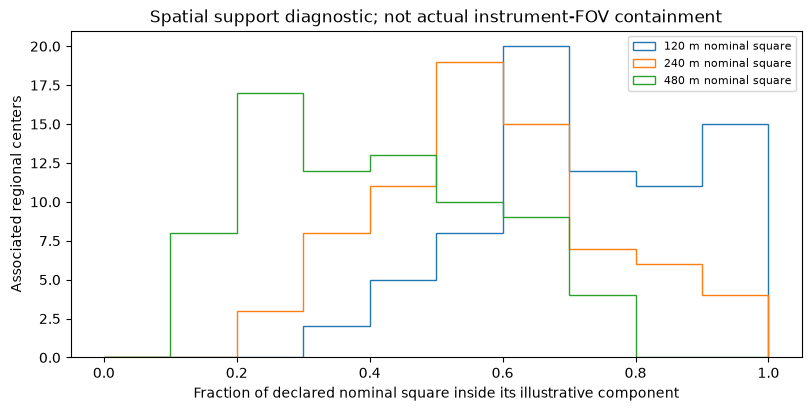

,candidate_id,region,nominal_box_side_m,associated_centers,overlap_q10,overlap_median,overlap_q90,full_nominal_boxes
1,A3CLR22_10_Leibnitz_Beta_Plateau:diagnostic_co...,A3CLR22_10_Leibnitz_Beta_Plateau,240.0,12,0.283737,0.543709,0.783409,0
4,A3CLR22_10_Leibnitz_Beta_Plateau:diagnostic_co...,A3CLR22_10_Leibnitz_Beta_Plateau,240.0,1,0.454550,0.454550,0.454550,0
7,A3CLR22_10_Leibnitz_Beta_Plateau:diagnostic_co...,A3CLR22_10_Leibnitz_Beta_Plateau,240.0,2,0.350462,0.435627,0.520792,0
10,A3CLR22_11_Malapert_Massif:diagnostic_componen...,A3CLR22_11_Malapert_Massif,240.0,12,0.549731,0.623047,0.744229,0
13,A3CLR22_11_Malapert_Massif:diagnostic_componen...,A3CLR22_11_Malapert_Massif,240.0,11,0.481547,0.657989,0.917455,0
16,A3CLR22_11_Malapert_Massif:diagnostic_componen...,A3CLR22_11_Malapert_Massif,240.0,4,0.547185,0.733161,0.903131,0
19,A3CLR22_12_deGerlache_Kocher_Massif:diagnostic...,A3CLR22_12_deGerlache_Kocher_Massif,240.0,3,0.512189,0.612809,0.621826,0
22,A3CLR22_12_deGerlache_Kocher_Massif:diagnostic...,A3CLR22_12_deGerlache_Kocher_Massif,240.0,1,0.584228,0.584228,0.584228,0
25,A3CLR22_12_deGerlache_Kocher_Massif:diagnostic...,A3CLR22_12_deGerlache_Kocher_Massif,240.0,3,0.359433,0.442286,0.498979,0
28,A3CLR22_2_Haworth:diagnostic_component_00014,A3CLR22_2_Haworth,240.0,4,0.559067,0.703794,0.862260,0


{'questions': ['Q39', 'Q40', 'Q41', 'Q42', 'Q43', 'Q44'],
 'regions': 7,
 'candidate_examples': 21,
 'documented_nominal_bin_size_m': 240.0,
 'associated_regional_centers': 73,
 'nominal_boxes_fully_in_component': 0,
 'median_nominal_box_component_overlap': 0.5624585349727612,
 'identity_control_rows_matching_Dar020': 714,
 'thermal_profile_rows': 3570,
 'limits': ['Nominal square geometry is a sensitivity diagnostic, not exact grid-affine reconstruction or radiometer FOV',
  'No physical co-registration established',
  'Overlap does not unmix the temperature average or define an adopted quality cutoff']}

In [2]:
profile=latest_completed_run(ROOT,'analysis/dar_017_lunar_site_profiles','20261106T163555259282Z_731d59')
with Run(ROOT,'analysis/dar_024_nominal_thermal_support',{'region_limit':REGION_LIMIT,'candidate_run':str(candidate.relative_to(ROOT)),
    'spatial_run':str(spatial.relative_to(ROOT)),'diagnostic_box_sides_m':[120,240,480],
    'overlap_diagnostic_cuts':[0,.25,.5,.75,1.],'box_interpretation':'nominal projected square diagnostic, not actual radiometer FOV or exact native grid affine',
    'physical_coregistration_established':False},'Moon/Site_Assessment/Dar_024_nominal_thermal_bin_support.ipynb') as run:
    register(run)
    examples=pd.read_csv(accepted_input(run,candidate,'candidate_manifest.csv'))
    meta=json.loads(accepted_input(run,spatial,'grid_metadata.json').read_text())
    spans=pd.read_csv(accepted_input(run,candidate,'associated_center_phase_spans.csv'))
    context=pd.read_csv(accepted_input(run,joint,'native_center_context.csv.gz'),usecols=['region','clon','clat','x_m','y_m'])
    products=json.loads(accepted_input(run,profile,'comparison_contract.json').read_text())['common_products']
    regions=regions_in(meta);examples=examples.loc[examples.region.isin(regions)]
    points=spans[['candidate_id','clon','clat']].merge(examples[['candidate_id','region','component_label']],on='candidate_id',validate='many_to_one')
    points=points.loc[points.region.isin(regions)].merge(context,on=['region','clon','clat'],how='left',validate='many_to_one',indicator=True)
    if not points._merge.eq('both').all():raise ValueError('Associated center missing accepted projected context')
    label=ROOT/'darrel stuff/data/moon/diviner/seasonal'/(products[0]+'.xml');run.input(label)
    nominal=documented_nominal_bin_size(label)
    if nominal!=240:raise ValueError('Declared nominal-size comparison differs from label')
    rows=[]
    for region in regions:
        grid=pd.read_csv(accepted_input(run,spatial,'grids/'+region+'.csv.gz'),usecols=['row','col','solar_visibility','earth_visibility','slope_deg'])
        labels=np.load(accepted_input(run,spatial,'labels/'+region+'.npy'))
        known=np.isfinite(grid.sort_values(['row','col'])[['solar_visibility','earth_visibility','slope_deg']]).all(axis=1).to_numpy().reshape(labels.shape)
        for point in points.loc[points.region.eq(region)].itertuples():
            m=meta[region];r=int(np.floor((m['top_m']-point.y_m)/m['spacing_m']));c=int(np.floor((point.x_m-m['left_m'])/m['spacing_m']))
            if not(0<=r<labels.shape[0] and 0<=c<labels.shape[1] and labels[r,c]==point.component_label):raise ValueError('Point association does not match pinned component')
            for side in [120.,nominal,480.]:
                result=nominal_box_overlap(point.x_m,point.y_m,point.component_label,labels,known,m,side)
                rows.append({'candidate_id':point.candidate_id,'region':region,'clon':point.clon,'clat':point.clat,
                    'nominal_box_side_m':side,**result})
    overlap=pd.DataFrame(rows);summaries=[]
    for row in examples.itertuples():
        for side in [120.,nominal,480.]:
            p=overlap.loc[overlap.candidate_id.eq(row.candidate_id)&overlap.nominal_box_side_m.eq(side)]
            summaries.append({'candidate_id':row.candidate_id,'region':row.region,'nominal_box_side_m':side,
                'associated_centers':len(p),'overlap_q10':p.component_overlap_fraction.quantile(.1),
                'overlap_median':p.component_overlap_fraction.median(),'overlap_q90':p.component_overlap_fraction.quantile(.9),
                'full_nominal_boxes':int(p.full_nominal_box_in_component.sum())})
    nominal_points=overlap.loc[overlap.nominal_box_side_m.eq(nominal)]
    profiles=[]
    for region in regions:
        source=accepted_input(run,environment,'paired_observations/'+region+'.csv.gz');pieces=[]
        point_ids=nominal_points.loc[nominal_points.region.eq(region),['candidate_id','clon','clat','component_overlap_fraction']]
        for chunk in pd.read_csv(source,usecols=['source_product','clon','clat','tbol','usable','complete_common_cohort'],chunksize=100_000):
            p=chunk.loc[chunk.source_product.isin(products)].merge(point_ids,on=['clon','clat'],how='inner',validate='many_to_one')
            if len(p):pieces.append(p)
        if not pieces:raise ValueError('Expected associated observations absent for region')
        observations=pd.concat(pieces,ignore_index=True);ids=examples.loc[examples.region.eq(region),'candidate_id'].tolist()
        for cut in [0.,.25,.5,.75,1.]:
            selected=observations.loc[observations.component_overlap_fraction.ge(cut-1e-10)]
            table=candidate_thermal_profiles(selected,ids,products);table['minimum_nominal_overlap']=cut;profiles.append(table)
    profiles=pd.concat(profiles,ignore_index=True)
    identity=profiles.loc[profiles.minimum_nominal_overlap.eq(0)].drop(columns='minimum_nominal_overlap')
    original=pd.read_csv(accepted_input(run,candidate,'candidate_common_product_thermal.csv'))
    original=original.loc[original.candidate_id.isin(examples.candidate_id)]
    keys=['candidate_id','cohort','source_product'];a=identity.set_index(keys).sort_index();b=original.set_index(keys).sort_index()
    if not a.index.equals(b.index):raise ValueError('Identity-control groups changed')
    for field in ['usable_centers','tbol_q10_K','tbol_median_K','tbol_q90_K']:np.testing.assert_allclose(a[field],b[field],equal_nan=True)
    overlap.to_csv(run.path('center_nominal_box_overlap.csv'),index=False)
    summary=pd.DataFrame(summaries);summary.to_csv(run.path('candidate_nominal_overlap_summary.csv'),index=False)
    profiles.to_csv(run.path('overlap_conditioned_thermal_profiles.csv'),index=False)
    supported=profiles.groupby(['candidate_id','cohort','minimum_nominal_overlap']).agg(
        supported_products=('usable_centers',lambda x:x.gt(0).sum()),total_center_product_rows=('usable_centers','sum'),
        median_of_observed_product_medians_K=('tbol_median_K','median')).reset_index()
    supported.to_csv(run.path('overlap_cohort_support.csv'),index=False)
    fig,ax=plt.subplots(figsize=(8,4),layout='constrained')
    for side,p in overlap.groupby('nominal_box_side_m'):
        ax.hist(p.component_overlap_fraction,bins=np.linspace(0,1,11),histtype='step',label=str(int(side))+' m nominal square')
    ax.set(xlabel='Fraction of declared nominal square inside its illustrative component',ylabel='Associated regional centers',title='Spatial support diagnostic; not actual instrument-FOV containment');ax.legend(fontsize=8)
    savefig(run,fig,'nominal_bin_overlap');display(summary.loc[summary.nominal_box_side_m.eq(nominal)])
    publish(run,{'questions':['Q%02d'%i for i in range(39,45)],'regions':len(regions),'candidate_examples':len(examples),
        'documented_nominal_bin_size_m':nominal,'associated_regional_centers':len(nominal_points),
        'nominal_boxes_fully_in_component':int(nominal_points.full_nominal_box_in_component.sum()),
        'median_nominal_box_component_overlap':float(nominal_points.component_overlap_fraction.median()),
        'identity_control_rows_matching_Dar020':len(identity),'thermal_profile_rows':len(profiles),
        'limits':['Nominal square geometry is a sensitivity diagnostic, not exact grid-affine reconstruction or radiometer FOV',
        'No physical co-registration established','Overlap does not unmix the temperature average or define an adopted quality cutoff']})
OUT=run.directory

## Findings and interpretation

The executed tables, plots and `findings.json` above contain the measured results. Undefined or absent groups are findings, not zero effects. Inspect the declared support/cohort controls rather than selecting whichever result looks most favourable.

## Outputs and next analysis

Generated tables/plots/provenance stay under `darrel stuff/data/processed/analysis/`. See [EDA notes](../../EDA_Notes.md) and [EDA results](../../EDA_Notes.md) for status/findings. Proposed algorithm consumption belongs in the [root overview/proposal](../../../Brief_Overview.md#algorithm-proposal), not a duplicated implementation plan here.